# **ML Assignment 3: Image Data**
**Dataset:** [Garbage Classification](https://www.kaggle.com/datasets/asdasdasasdas/garbage-classification)

# 1. Download and Import Data

In [1]:
!pip install -q kagglehub timm
import os
import shutil
import kagglehub
from sklearn.model_selection import train_test_split

# Download latest version via kagglehub (Google Colab standard way)
path = kagglehub.dataset_download("asdasdasasdas/garbage-classification")
print("Path to dataset files:", path)

# Dynamically locate the directory containing the 6 garbage class folders
expected_classes = {"cardboard", "glass", "metal", "paper", "plastic", "trash"}
raw_images_root = None
for root, dirs, files in os.walk(path):
    if expected_classes.issubset(set(d.lower() for d in dirs)):
        raw_images_root = root
        break

if raw_images_root is None:
    raise FileNotFoundError(f"Could not find garbage class folders inside {path}")

print("Found raw class folders at:", raw_images_root)

# Build stratified 70% train / 15% valid / 15% test folders in /content/datasets/
base_split_dir = "/content/datasets"
if os.path.exists(base_split_dir):
    shutil.rmtree(base_split_dir)

valid_exts = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
all_img_paths, all_labels = [], []

for cls_name in sorted(os.listdir(raw_images_root)):
    cls_dir = os.path.join(raw_images_root, cls_name)
    if not os.path.isdir(cls_dir):
        continue
    for fname in sorted(os.listdir(cls_dir)):
        if fname.lower().endswith(valid_exts):
            all_img_paths.append(os.path.join(cls_dir, fname))
            all_labels.append(cls_name)

# 70% train, 30% temp -> split temp 50/50 into 15% valid and 15% test
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    all_img_paths, all_labels, test_size=0.30, random_state=42, stratify=all_labels
)
val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths, temp_labels, test_size=0.50, random_state=42, stratify=temp_labels
)

splits = {
    "train": (train_paths, train_labels),
    "valid": (val_paths, val_labels),
    "test": (test_paths, test_labels),
}

for split_name, (paths_list, labels_list) in splits.items():
    for src_path, cls_name in zip(paths_list, labels_list):
        dst_dir = os.path.join(base_split_dir, split_name, cls_name)
        os.makedirs(dst_dir, exist_ok=True)
        shutil.copy2(src_path, os.path.join(dst_dir, os.path.basename(src_path)))

print(f"Prepared splits in {base_split_dir}: train={len(train_paths)}, valid={len(val_paths)}, test={len(test_paths)}")

Using Colab cache for faster access to the 'garbage-classification' dataset.
Path to dataset files: /kaggle/input/garbage-classification
Found raw class folders at: /kaggle/input/garbage-classification/Garbage classification/Garbage classification
Prepared splits in /content/datasets: train=1768, valid=379, test=380


In [2]:
import os
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from collections import defaultdict
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision
import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder
import timm
from timm.data import resolve_data_config
from timm.data.transforms_factory import create_transform
import sys
from tqdm.notebook import tqdm
import time
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

# 2. EDA (Exploratory Data Analysis)

In [3]:
# Define the data directories
train_data_dir = '/content/datasets/train/'
val_data_dir = '/content/datasets/valid/'
test_data_dir = '/content/datasets/test/'

Image size, number of channels and label count

In [4]:
# image size, num_channels of train/validation/test dataset
def get_unique_info(data_dir, name="Dataset"):
    sizes = set()
    channels = set()
    mode_set = set()
    ds = ImageFolder(data_dir, transform=None)
    for img, _ in ds:
        sizes.add(img.size)  # (width, height)
        mode = img.mode
        mode_set.add(mode)
        if mode == "RGB":
            channels.add(3)
        elif mode in ["L", "1", "P"]:
            channels.add(1)
        elif mode == "RGBA":
            channels.add(4)
        elif mode == "CMYK":
            channels.add(4)
        else:
            channels.add(f"Unknown ({mode})")
    print(f"{name} set:")
    print(f"  Total images: {len(ds)}")
    print("  Image sizes:", *list(sizes)[:10], ("..." if len(sizes) > 10 else ""))
    print("  Number channel counts:", *list(channels))
    print("  Color modes:", *list(mode_set))


get_unique_info(train_data_dir, "Train")
print('--------------------------')
get_unique_info(val_data_dir, "Validation")
print('--------------------------')
get_unique_info(test_data_dir, "Test")

Train set:
  Total images: 1768
  Image sizes: (512, 384) 
  Number channel counts: 3
  Color modes: RGB
--------------------------
Validation set:
  Total images: 379
  Image sizes: (512, 384) 
  Number channel counts: 3
  Color modes: RGB
--------------------------
Test set:
  Total images: 380
  Image sizes: (512, 384) 
  Number channel counts: 3
  Color modes: RGB


In [5]:
# labels name
target_to_class = {v: k for k, v in ImageFolder(train_data_dir).class_to_idx.items()}
NUM_CLASSES = len(target_to_class)
print(f'Label size: {NUM_CLASSES}')
target_to_class

Label size: 6


{0: 'cardboard', 1: 'glass', 2: 'metal', 3: 'paper', 4: 'plastic', 5: 'trash'}

Some sample image visualization

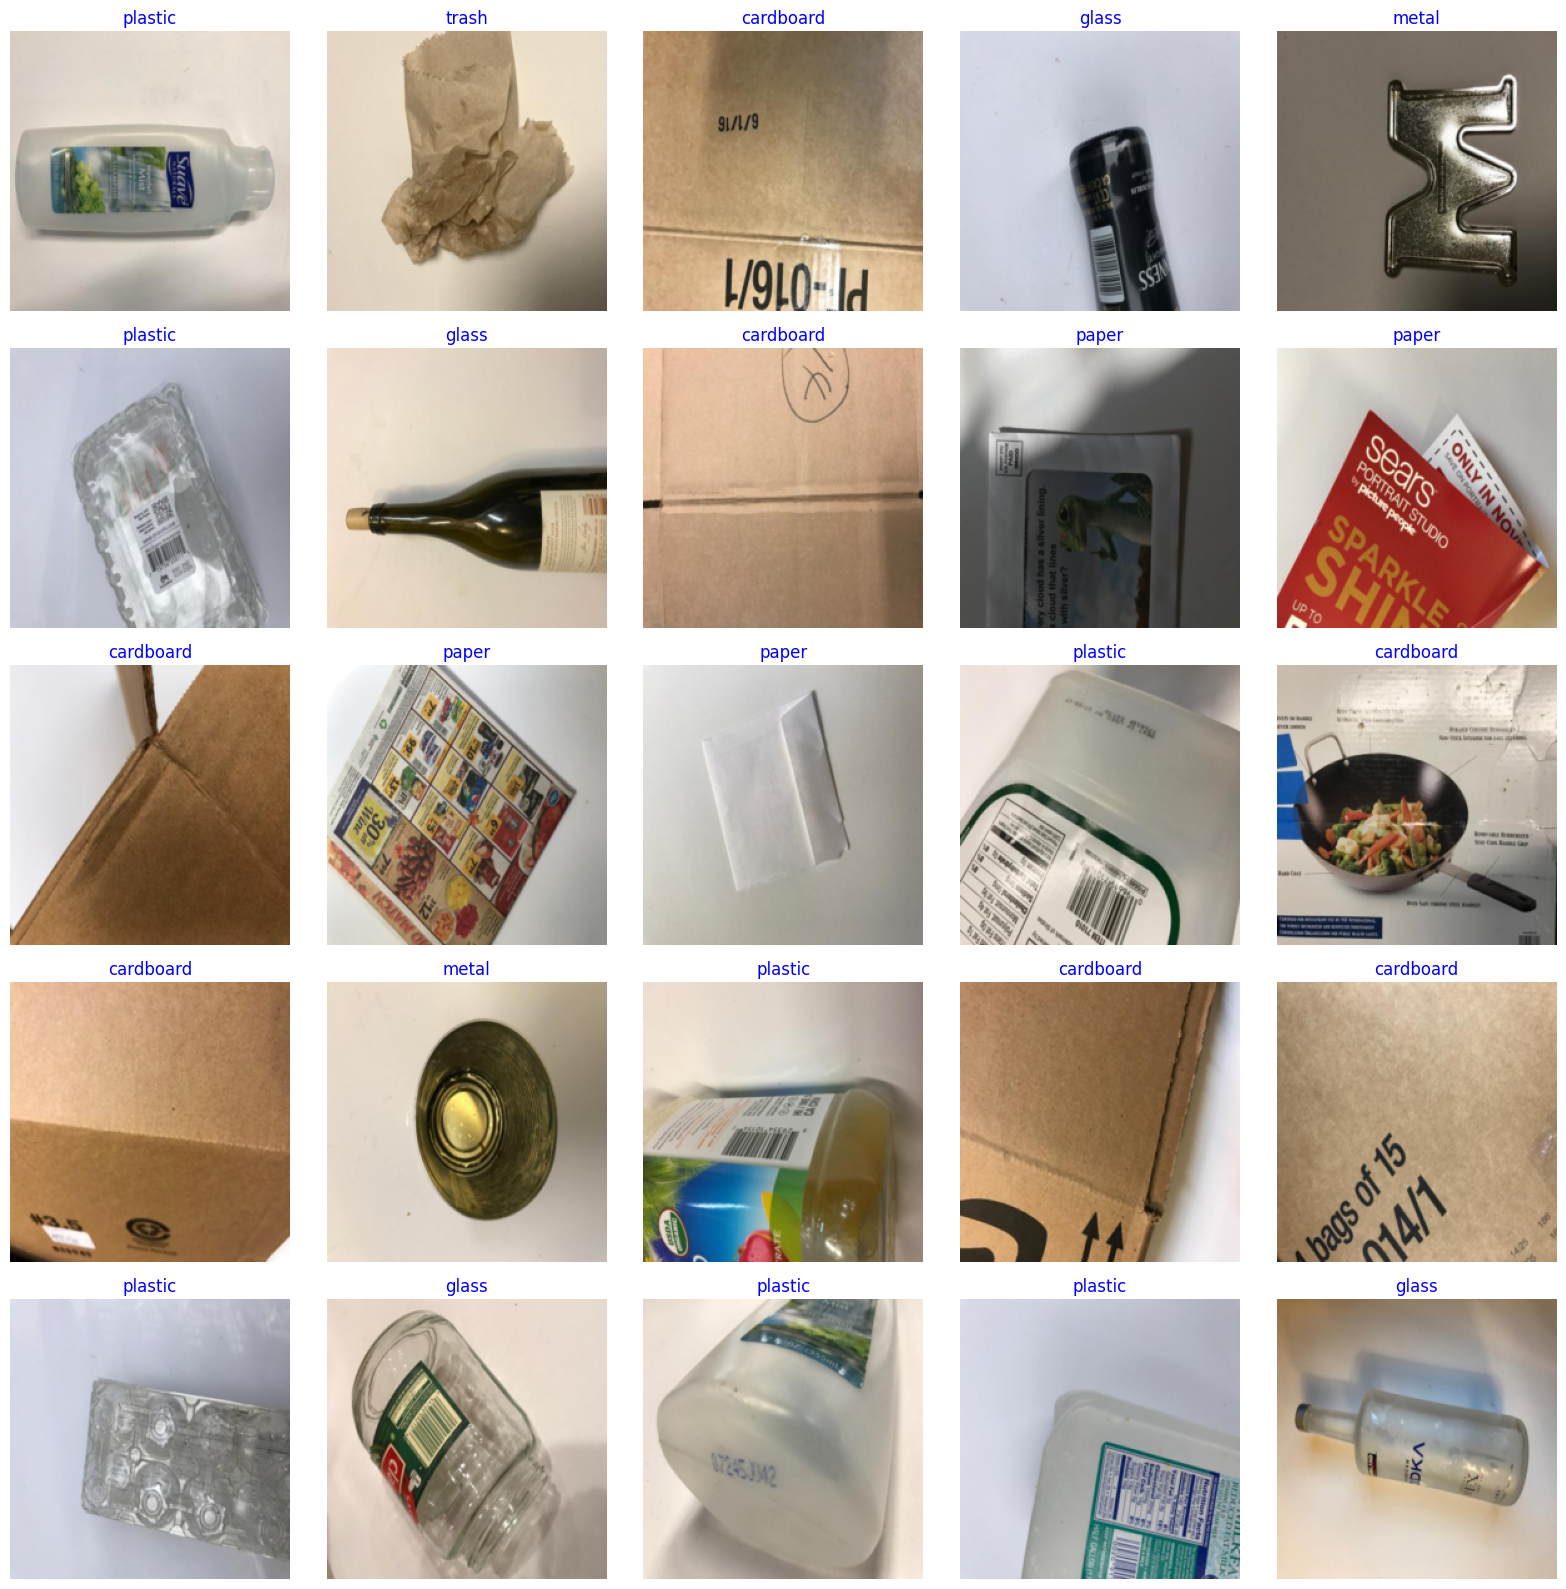

In [6]:
# sample image visualization
def show_images(data_dir, batch_size, n=25):
    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
    ])
    ds = ImageFolder(data_dir, transform=transform)
    loader = DataLoader(ds, batch_size=batch_size, shuffle=True)
    images, labels = next(iter(loader))
    target_to_class = {v: k for k, v in ds.class_to_idx.items()}
    classes = list(target_to_class.values())
    plt.figure(figsize=(16, 16))
    sample = min(n, len(images))
    for i in range(sample):
        plt.subplot(5, 5, i + 1)
        img = images[i].permute(1, 2, 0).numpy()
        plt.imshow(img)
        class_name = classes[labels[i]]
        plt.title(class_name, color='blue', fontsize=12)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

batch_size = 40
show_images(train_data_dir, batch_size)

Label distribution

In [7]:
# eda helper function for label distribution
def perform_eda(data_dir, set_name):
    """Performs EDA on a specified dataset directory, focusing on label distribution."""
    if not os.path.exists(data_dir):
        print(f"Directory not found: {data_dir}. Skipping EDA for {set_name} set.")
        return

    classes = sorted([c for c in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, c))])
    class_counts = {cls: len(os.listdir(os.path.join(data_dir, cls))) for cls in classes}
    total_images = sum(class_counts.values())

    class_df = pd.DataFrame(class_counts.items(), columns=['Class', 'Count'])
    class_df = class_df.sort_values(by='Count', ascending=False)

    print(f'\n--- {set_name} Set EDA ---')
    print(f'Total images: {total_images}')
    print(f'Total classes: {len(classes)}')
    print('Image distribution per class:')
    print(class_df.to_string(index=False))

    plt.style.use('seaborn-v0_8-whitegrid')
    plt.figure(figsize=(10, 6))
    bars = plt.bar(class_df['Class'], class_df['Count'], color='#CCFF99', edgecolor='#558833')

    plt.title(f'Image Distribution per Class ({set_name} Set)', fontsize=16, fontweight='bold')
    plt.xlabel('Class Name', fontsize=14)
    plt.ylabel('Number of Images', fontsize=14)
    plt.xticks(rotation=30, fontsize=13)

    for bar in bars:
        height = bar.get_height()
        plt.text(bar.get_x() + bar.get_width() / 2., height,
                 '%d' % int(height), ha='center', va='bottom', fontsize=13)

    plt.tight_layout()
    plt.show()


--- Training Set EDA ---
Total images: 1768
Total classes: 6
Image distribution per class:
    Class  Count
    paper    416
    glass    350
  plastic    337
    metal    287
cardboard    282
    trash     96


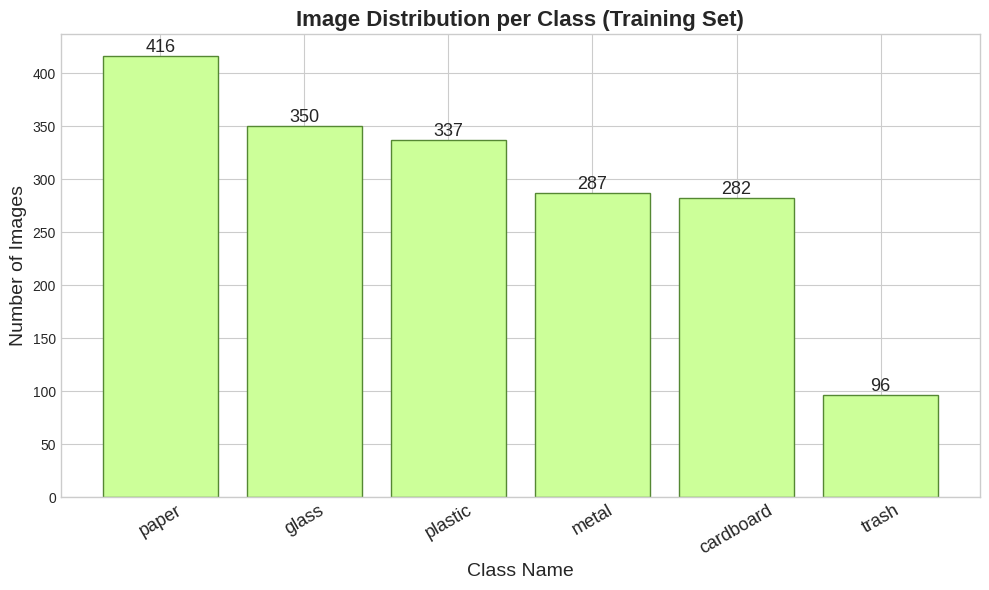

In [8]:
# label distribution of train dataset
perform_eda(train_data_dir, 'Training')


--- Validation Set EDA ---
Total images: 379
Total classes: 6
Image distribution per class:
    Class  Count
    paper     89
    glass     75
  plastic     72
cardboard     61
    metal     61
    trash     21


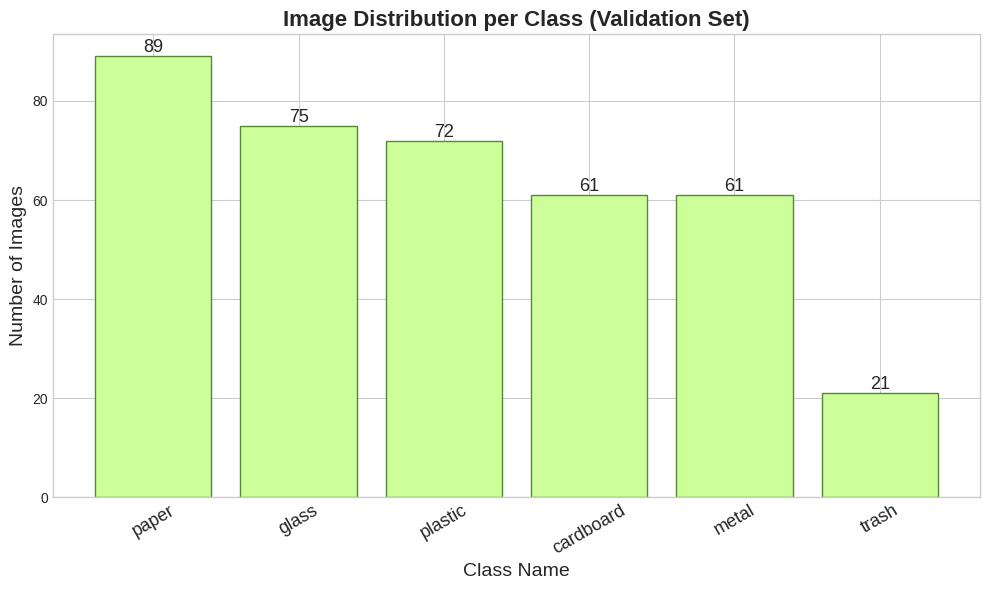

In [9]:
# label distribution of valid dataset
perform_eda(val_data_dir, 'Validation')


--- Test Set EDA ---
Total images: 380
Total classes: 6
Image distribution per class:
    Class  Count
    paper     89
    glass     76
  plastic     73
    metal     62
cardboard     60
    trash     20


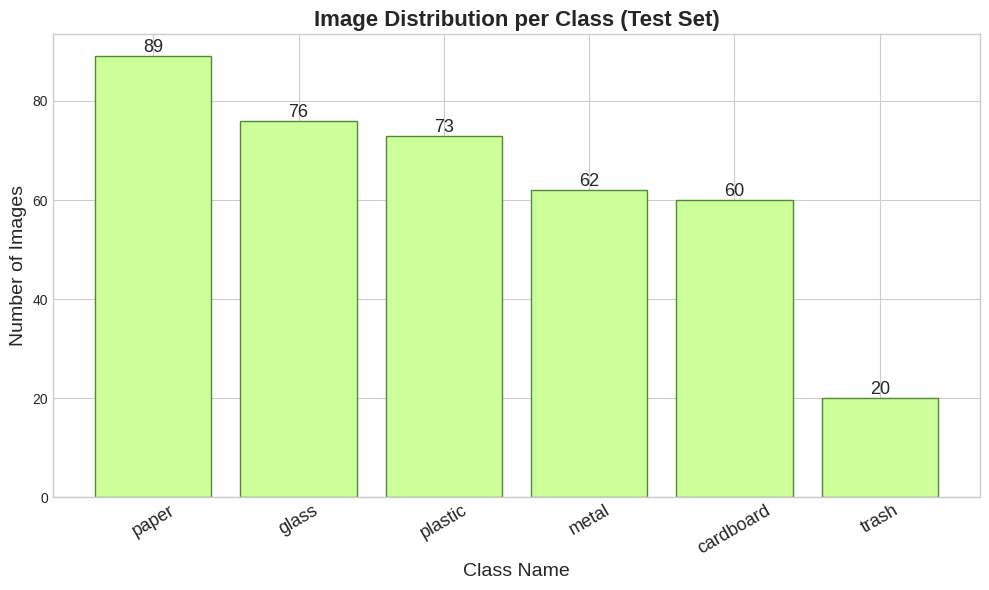

In [10]:
# label distribution of test dataset
perform_eda(test_data_dir, 'Test')

Color channel distribution


--- Average Channel Values per Class ---
             R_avg    G_avg    B_avg
cardboard 170.08   148.86   127.93  
glass     176.38   170.52   163.10  
metal     164.83   157.01   151.90  
paper     172.18   164.55   155.43  
plastic   171.08   170.09   168.98  
trash     178.80   166.11   149.05  


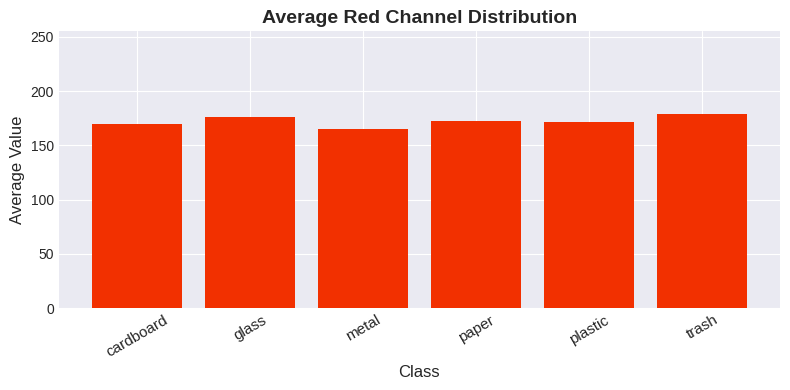

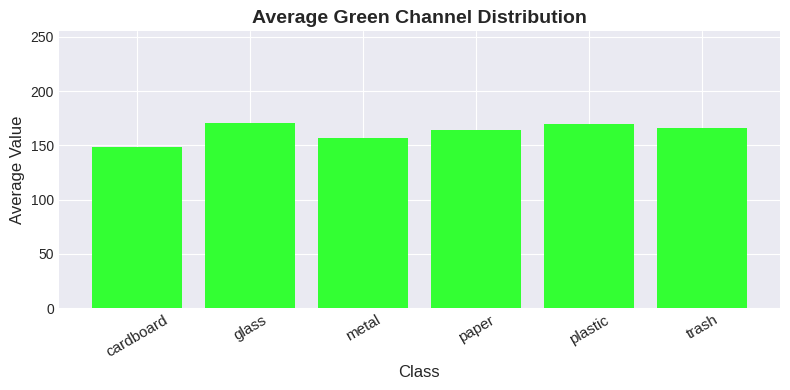

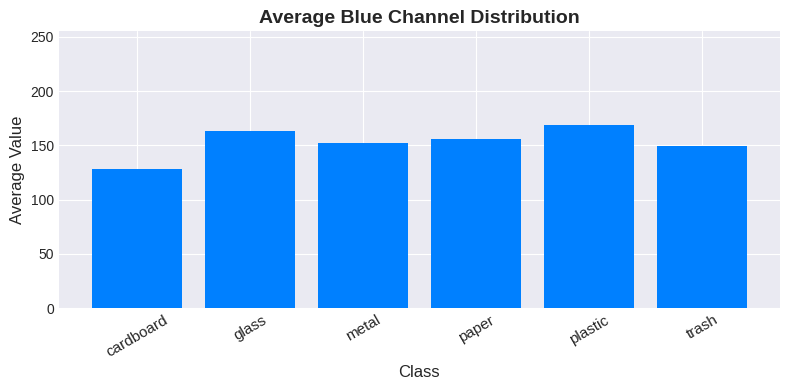

In [11]:
# helper function for color channel distribution
def analyze_average_channels():
    """Analyzes and visualizes the average R, G, B channel values for each class across the entire dataset."""
    DATA_DIRECTORIES = {
        'train': train_data_dir,
        'valid': val_data_dir,
        'test': test_data_dir
    }

    all_data = defaultdict(lambda: {'R': [], 'G': [], 'B': []})
    for set_name, data_dir in DATA_DIRECTORIES.items():
        if not os.path.exists(data_dir):
            continue
        classes = sorted(os.listdir(data_dir))
        for cls in classes:
            class_path = os.path.join(data_dir, cls)
            if os.path.isdir(class_path):
                for img_name in os.listdir(class_path):
                    img_path = os.path.join(class_path, img_name)
                    try:
                        with Image.open(img_path) as img:
                            img = img.convert('RGB')
                            img_np = np.array(img)
                            all_data[cls]['R'].append(img_np[:, :, 0].mean())
                            all_data[cls]['G'].append(img_np[:, :, 1].mean())
                            all_data[cls]['B'].append(img_np[:, :, 2].mean())
                    except Exception as e:
                        print(f"Could not read image {img_path}: {e}")

    average_data = {
        cls: {
            'R_avg': np.mean(all_data[cls]['R']),
            'G_avg': np.mean(all_data[cls]['G']),
            'B_avg': np.mean(all_data[cls]['B'])
        } for cls in all_data
    }

    avg_df = pd.DataFrame(average_data).T
    pd.options.display.float_format = '{:.2f}  '.format
    print("\n--- Average Channel Values per Class ---")
    print(avg_df.to_string())

    colors = ['#F23000', '#33FF33', '#0080FF']
    labels = ['Red', 'Green', 'Blue']
    channels_to_plot = ['R_avg', 'G_avg', 'B_avg']
    for i, channel in enumerate(channels_to_plot):
        plt.style.use('seaborn-v0_8-darkgrid')
        plt.figure(figsize=(8, 4))

        plt.bar(avg_df.index, avg_df[channel], color=colors[i])

        plt.title(f'Average {labels[i]} Channel Distribution', fontsize=14, fontweight='bold')
        plt.xlabel('Class', fontsize=12)
        plt.ylabel('Average Value', fontsize=12)
        plt.xticks(rotation=30, fontsize=11)
        plt.ylim(0, 255)

        plt.tight_layout()
        plt.show()

# Run the analysis
analyze_average_channels()

# 3. Extract feature vector

Set `EXTRACT_FEATURES` to `True` to extract and save the feature vectors, or to `False` to reuse previously extracted `.npy` features stored in `/content/features/`. It uses these 5 pretrained models to generate and save feature vectors:
 - `resnet18`
 - `resnet34`
 - `resnet50`
 - `efficientnet_b0`
 - `efficientnet_b3`

In [12]:
EXTRACT_FEATURES = True

In [13]:
class GarbageDataset(Dataset):
    def __init__(self, data_dir, transform=None):
        self.data = ImageFolder(data_dir, transform=transform)
        self.target_to_class = {v: k for k, v in self.data.class_to_idx.items()}

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        return self.data[idx]

    @property
    def classes(self):
        return self.data.classes

    def get_class_name(self, idx):
        return self.target_to_class[idx]

In [14]:
# function for extracting and saving feature vectors
def extract_features(model_name: str,
                     input_size=(224, 224),
                     batch_size=32,
                     data_dir='/content/datasets'):
    print(f"--- Extracting features with {model_name} ---")
    model = timm.create_model(model_name, pretrained=True)
    config = resolve_data_config(model.pretrained_cfg)
    config['input_size'] = (3, *input_size)
    transform = create_transform(**config)
    model.reset_classifier(0)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = model.to(device)
    model.eval()

    feat_dir = f'/content/features/{model_name}'
    os.makedirs(feat_dir, exist_ok=True)

    for split in ['train', 'valid', 'test']:
        ds = GarbageDataset(os.path.join(data_dir, split), transform=transform)
        loader = DataLoader(ds, batch_size=batch_size, shuffle=False, num_workers=2)
        features_list, labels_list = [], []
        with torch.no_grad():
            for imgs, labels in tqdm(loader, desc=f'Extracting {split} set'):
                feats = model(imgs.to(device))
                feats = feats.cpu().numpy()
                features_list.append(feats)
                labels_list.append(labels.numpy())
        features = np.concatenate(features_list, axis=0)
        labels = np.concatenate(labels_list, axis=0)
        np.save(f'{feat_dir}/{split}_features.npy', features)
        np.save(f'{feat_dir}/{split}_labels.npy', labels)
        print(f"  {split}: features={features.shape}, labels={labels.shape}")
    print(f"{model_name} features saved.\n")

In [15]:
# extract feature vectors using resnet18/34/50 and efficientnet_b0/b3 pretrained models
base_models = ['resnet18', 'resnet34', 'resnet50', 'efficientnet_b0', 'efficientnet_b3']
if EXTRACT_FEATURES:
    for base_model in base_models:
        extract_features(base_model)
else:
    print("Feature extraction skipped.")

--- Extracting features with resnet18 ---


model.safetensors: reconstructing file:   0%|          |  0.00B / 46.8MB            

model.safetensors: downloading bytes:           |  0.00B            

Extracting train set:   0%|          | 0/56 [00:00<?, ?it/s]

  train: features=(1768, 512), labels=(1768,)


Extracting valid set:   0%|          | 0/12 [00:00<?, ?it/s]

... (31 outputs left out)

Extracting valid set:   0%|          | 0/12 [00:00<?, ?it/s]

  valid: features=(379, 1536), labels=(379,)


Extracting test set:   0%|          | 0/12 [00:00<?, ?it/s]

  test: features=(380, 1536), labels=(380,)
efficientnet_b3 features saved.



In [16]:
# Verify or unzip pre-extracted feature vectors if EXTRACT_FEATURES is False
if not EXTRACT_FEATURES:
    if os.path.exists('/content/features/resnet18/train_features.npy'):
        print("Using existing pre-extracted features in /content/features/")
    elif os.path.exists('features_garbage.zip'):
        import zipfile
        with zipfile.ZipFile('features_garbage.zip', 'r') as zip_ref:
            zip_ref.extractall('/content/')
        print("Extracted features_garbage.zip into /content/")
    else:
        raise FileNotFoundError(
            "Pre-extracted features not found. Set EXTRACT_FEATURES = True to extract them first."
        )

# 4. Modeling

Set `TRAIN_MODEL` to `True` to train all models from scratch and save results to `model_result_garbage.csv`, or set to `False` to load previously saved results. With 2,527 images on a Colab GPU, full training typically takes ~5–10 minutes.

In [17]:
TRAIN_MODEL = True

## Traditional models

Using traditional ML models with the configurations below on pre-extracted feature vectors:

1. Logistic Regression, `penalty`: `l2`, `None`
2. Random Forest, `n_estimators`: `100`, `150`
3. SVM, `C`: `1`, `10`

In [18]:
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

logistic_config = [{"penalty": p, "random_state": 42, "max_iter": 1000} for p in ["l2", None]]
forest_config = [{"n_estimators": n, "random_state": 42, "n_jobs": -1} for n in [100, 150]]
svm_config = [{"C": n, "kernel": "linear", "random_state": 42} for n in [1, 10]]

models = {
    'Logistic Regression': (LogisticRegression, logistic_config),
    'Random Forest': (RandomForestClassifier, forest_config),
    'SVM': (SVC, svm_config),
}
model_result = pd.DataFrame(columns=[
    "base_model",
    "classifier",
    "model_config",
    "accuracy",
    "precision",
    "recall",
    "f1"
])

Train traditional ML models on extracted features across all 5 backbones

In [19]:
# train traditional models
base_models = ['resnet18', 'resnet34', 'resnet50', 'efficientnet_b0', 'efficientnet_b3']
if TRAIN_MODEL:
    for name, (classifier, model_configs) in models.items():
        start_time = time.time()
        for model_config in model_configs:
            model = classifier(**model_config)
            cfg_key, cfg_val = list(model_config.items())[0]
            for base_model in tqdm(base_models, desc=f"Training {name}/{cfg_key}:{cfg_val}"):
                print(f"Training {name}/{base_model}...")
                train_features = np.load(f'/content/features/{base_model}/train_features.npy')
                train_labels = np.load(f'/content/features/{base_model}/train_labels.npy')
                test_features = np.load(f'/content/features/{base_model}/test_features.npy')
                test_labels = np.load(f'/content/features/{base_model}/test_labels.npy')

                model.fit(train_features, train_labels)
                preds = model.predict(test_features)

                accuracy = accuracy_score(test_labels, preds)
                precision = precision_score(test_labels, preds, average="macro", zero_division=0)
                recall = recall_score(test_labels, preds, average="macro", zero_division=0)
                f1 = f1_score(test_labels, preds, average="macro", zero_division=0)

                model_result.loc[len(model_result)] = [
                    base_model,
                    name,
                    cfg_val,
                    accuracy, precision, recall, f1
                ]
        end_time = time.time()
        elapsed_time = int(end_time - start_time)
        print(f"\nElapsed time for {name}: {elapsed_time // 60} minutes {elapsed_time % 60} seconds\n")
else:
    print("Training skipped.")

Training Logistic Regression/penalty:l2:   0%|          | 0/5 [00:00<?, ?it/s]

Training Logistic Regression/resnet18...
Training Logistic Regression/resnet34...
Training Logistic Regression/resnet50...
Training Logistic Regression/efficientnet_b0...
Training Logistic Regression/efficientnet_b3...


Training Logistic Regression/penalty:None:   0%|          | 0/5 [00:00<?, ?it/s]

Training Logistic Regression/resnet18...
Training Logistic Regression/resnet34...
Training Logistic Regression/resnet50...
Training Logistic Regression/efficientnet_b0...
Training Logistic Regression/efficientnet_b3...

Elapsed time for Logistic Regression: 0 minutes 13 seconds



Training Random Forest/n_estimators:100:   0%|          | 0/5 [00:00<?, ?it/s]

Training Random Forest/resnet18...
Training Random Forest/resnet34...
Training Random Forest/resnet50...
Training Random Forest/efficientnet_b0...
Training Random Forest/efficientnet_b3...


... (2 outputs left out)

Training SVM/C:1:   0%|          | 0/5 [00:00<?, ?it/s]

Training SVM/resnet18...
Training SVM/resnet34...
Training SVM/resnet50...
Training SVM/efficientnet_b0...
Training SVM/efficientnet_b3...


Training SVM/C:10:   0%|          | 0/5 [00:00<?, ?it/s]

Training SVM/resnet18...
Training SVM/resnet34...
Training SVM/resnet50...
Training SVM/efficientnet_b0...
Training SVM/efficientnet_b3...

Elapsed time for SVM: 0 minutes 8 seconds



## Deep learning models
End-to-end fine-tuning and head-classifier fine-tuning (using extracted feature vectors while the pretrained backbone remains frozen) with these pretrained models:
 - `resnet18`
 - `resnet34`
 - `resnet50`
 - `efficientnet_b0`
 - `efficientnet_b3`

In [20]:
# define classes used for deep learning models
class FeatureDataset(Dataset):
    def __init__(self, base_model, split):
        features = np.load(f'/content/features/{base_model}/{split}_features.npy')
        labels = np.load(f'/content/features/{base_model}/{split}_labels.npy')
        self.x = torch.tensor(features, dtype=torch.float32)
        self.y = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.x)

    def __getitem__(self, idx):
        return self.x[idx], self.y[idx]


class GarbageClassifierNet(nn.Module):
    def __init__(self, base_name, num_classes=6, end_to_end=True):
        base_out_map = {
            'resnet18': 512,
            'resnet34': 512,
            'resnet50': 2048,
            'efficientnet_b0': 1280,
            'efficientnet_b3': 1536,
        }
        if base_name not in base_out_map:
            raise ValueError("Invalid base model name")
        base_out = base_out_map[base_name]

        super(GarbageClassifierNet, self).__init__()
        if end_to_end:
            self.base_model = timm.create_model(base_name, pretrained=True, num_classes=0)
            self.f = self.base_model
        else:
            self.f = nn.Identity()
            self.base_model = None

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(base_out, num_classes),
        )

    def forward(self, x):
        x = self.f(x)
        output = self.classifier(x)
        return output


class GarbageClassifier(nn.Module):
    def __init__(self,
                 base_name='efficientnet_b3',
                 num_classes=6,
                 batch_size=32,
                 end_to_end=True):
        super(GarbageClassifier, self).__init__()
        self.end_to_end = end_to_end
        self.nn_net = GarbageClassifierNet(base_name, num_classes, end_to_end)
        self.device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
        self.to(self.device)

        if not end_to_end:
            train_ds = FeatureDataset(base_name, 'train')
            val_ds = FeatureDataset(base_name, 'valid')
            test_ds = FeatureDataset(base_name, 'test')
        else:
            config = resolve_data_config(self.nn_net.base_model.pretrained_cfg)
            config['input_size'] = (3, 224, 224)
            transform = create_transform(**config)
            train_ds = GarbageDataset(data_dir='/content/datasets/train', transform=transform)
            val_ds = GarbageDataset(data_dir='/content/datasets/valid', transform=transform)
            test_ds = GarbageDataset(data_dir='/content/datasets/test', transform=transform)

        self.train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
        self.val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False)
        self.test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False)

    def fit_model(self, num_epochs=5, lr=None, plot_result=True):
        if lr is None:
            lr = 1e-4 if self.end_to_end else 1e-3

        train_losses, val_losses = [], []
        self.nn_net.to(self.device)
        criterion = nn.CrossEntropyLoss()
        optimizer = optim.Adam(self.nn_net.parameters(), lr=lr)

        for epoch in range(num_epochs):
            self.nn_net.train()
            running_loss = 0.0
            for images, labels in tqdm(self.train_loader, desc=f'Epoch {epoch+1}/{num_epochs} [Train]'):
                images, labels = images.to(self.device), labels.to(self.device)

                optimizer.zero_grad()
                outputs = self.nn_net(images)
                loss = criterion(outputs, labels)
                loss.backward()
                optimizer.step()
                running_loss += loss.item() * labels.size(0)

            train_loss = running_loss / len(self.train_loader.dataset)
            train_losses.append(train_loss)

            self.nn_net.eval()
            running_loss = 0.0
            with torch.no_grad():
                for images, labels in tqdm(self.val_loader, desc=f'Epoch {epoch+1}/{num_epochs} [Valid]'):
                    images, labels = images.to(self.device), labels.to(self.device)
                    outputs = self.nn_net(images)
                    loss = criterion(outputs, labels)
                    running_loss += loss.item() * labels.size(0)
            val_loss = running_loss / len(self.val_loader.dataset)
            val_losses.append(val_loss)
            print(f"Epoch {epoch+1}/{num_epochs} - Train loss: {train_loss:.4f}, Validation loss: {val_loss:.4f}")

        if plot_result:
            plt.plot(train_losses, label='Training loss')
            plt.plot(val_losses, label='Validation loss')
            plt.legend()
            plt.title("Loss over epochs")
            plt.show()

    def evaluate(self):
        self.nn_net.eval()
        preds_list = []
        labels_list = []
        with torch.no_grad():
            for images, labels in self.test_loader:
                images, labels = images.to(self.device), labels.to(self.device)
                outputs = self.nn_net(images)
                _, preds = torch.max(outputs, 1)
                preds_list.extend(preds.cpu().numpy())
                labels_list.extend(labels.cpu().numpy())
        preds_list = np.array(preds_list)
        labels_list = np.array(labels_list)
        acc = accuracy_score(labels_list, preds_list)
        prec = precision_score(labels_list, preds_list, average="macro", zero_division=0)
        rec = recall_score(labels_list, preds_list, average="macro", zero_division=0)
        f1 = f1_score(labels_list, preds_list, average="macro", zero_division=0)
        return acc, prec, rec, f1

Train deep models (`end_to_end` and `head_classifier`) across all 5 pretrained backbones (recommended with Colab GPU)

In [21]:
# train deep models
base_models = ['resnet18', 'resnet34', 'resnet50', 'efficientnet_b0', 'efficientnet_b3']
if TRAIN_MODEL:
    start_time = time.time()
    for fine_tuning in ['end_to_end', 'head_classifier']:
        for base_model in base_models:
            print(f"Training Deep Model with {base_model}/{fine_tuning}...")
            torch.manual_seed(42)
            model = GarbageClassifier(
                base_name=base_model,
                num_classes=NUM_CLASSES,
                end_to_end=(fine_tuning == 'end_to_end')
            )
            model.fit_model(num_epochs=5, plot_result=False)
            accuracy, precision, recall, f1 = model.evaluate()
            model_result.loc[len(model_result)] = [
                base_model,
                "MLP",
                fine_tuning,
                accuracy, precision, recall, f1
            ]
            print(f'{base_model}/{fine_tuning}: Accuracy: {accuracy:.4f}, Precision: {precision:.4f}, Recall: {recall:.4f}, F1: {f1:.4f}\n')
    end_time = time.time()
    elapsed_time = int(end_time - start_time)
    print(f"\nElapsed time: {elapsed_time // 60} minutes {elapsed_time % 60} seconds\n")
else:
    print("Training skipped.")

Training Deep Model with resnet18/end_to_end...


Epoch 1/5 [Train]:   0%|          | 0/56 [00:00<?, ?it/s]

Epoch 1/5 [Valid]:   0%|          | 0/12 [00:00<?, ?it/s]

Epoch 1/5 - Train loss: 1.6774, Validation loss: 1.5222


Epoch 2/5 [Train]:   0%|          | 0/56 [00:00<?, ?it/s]

Epoch 2/5 [Valid]:   0%|          | 0/12 [00:00<?, ?it/s]

... (141 outputs left out)

Epoch 4/5 - Train loss: 0.3298, Validation loss: 0.4175


Epoch 5/5 [Train]:   0%|          | 0/56 [00:00<?, ?it/s]

Epoch 5/5 [Valid]:   0%|          | 0/12 [00:00<?, ?it/s]

Epoch 5/5 - Train loss: 0.2840, Validation loss: 0.4038
efficientnet_b3/head_classifier: Accuracy: 0.8474, Precision: 0.8317, Recall: 0.8062, F1: 0.8156


Elapsed time: 11 minutes 15 seconds



In [22]:
RESULTS_CSV = "model_result_garbage.csv"
if TRAIN_MODEL:
    model_result.to_csv(RESULTS_CSV, index=False)
    print(f"Saved results to {RESULTS_CSV}")

Saved results to model_result_garbage.csv


## Comparing models

In [23]:
# load model result if not retrained
if not TRAIN_MODEL:
    if os.path.exists(RESULTS_CSV):
        model_result = pd.read_csv(RESULTS_CSV)
        print(f"Loaded results from {RESULTS_CSV}")
    else:
        raise FileNotFoundError(
            f"{RESULTS_CSV} not found. Set TRAIN_MODEL = True to train and generate results first."
        )

In [24]:
model_result = model_result.fillna("None")
model_result.info()

<class 'pandas.core.frame.DataFrame'>
Index: 40 entries, 0 to 39
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   base_model    40 non-null     object 
 1   classifier    40 non-null     object 
 2   model_config  40 non-null     object 
 3   accuracy      40 non-null     float64
 4   precision     40 non-null     float64
 5   recall        40 non-null     float64
 6   f1            40 non-null     float64
dtypes: float64(4), object(3)
memory usage: 2.5+ KB


In [25]:
model_result

,base_model,classifier,model_config,accuracy,precision,recall,f1
0,resnet18,Logistic Regression,l2,0.82,0.82,0.79,0.80
1,resnet34,Logistic Regression,l2,0.85,0.83,0.81,0.82
2,resnet50,Logistic Regression,l2,0.90,0.89,0.87,0.88
3,efficientnet_b0,Logistic Regression,l2,0.89,0.88,0.87,0.87
4,efficientnet_b3,Logistic Regression,l2,0.87,0.86,0.84,0.85
5,resnet18,Logistic Regression,None,0.80,0.80,0.77,0.78
6,resnet34,Logistic Regression,None,0.82,0.80,0.79,0.79
7,resnet50,Logistic Regression,None,0.90,0.88,0.86,0.87
8,efficientnet_b0,Logistic Regression,None,0.87,0.86,0.85,0.86
9,efficientnet_b3,Logistic Regression,None,0.87,0.86,0.84,0.85


In [26]:
def highlight_row(row, idx):
    if row.name == idx:
        return ["background-color: gold"] * len(row)
    else:
        return [""] * len(row)

In [27]:
from IPython.display import display

model_names = model_result.classifier.unique()
model_max_f1 = []
for name in model_names:
    df_result = model_result[model_result["classifier"] == name]
    max_f1_row_idx = df_result["f1"].idxmax()
    model_max_f1.append(max_f1_row_idx)
    styled_result = df_result.style.apply(highlight_row, axis=1, idx=max_f1_row_idx)

    print(f"{name} result:")
    display(styled_result)
    print(f"=> The best configuration for {name} is: f1-score = {df_result.loc[max_f1_row_idx, 'f1']:.4f}")
    print("* Model config")
    print(f"  - Pretrained base model: {df_result.loc[max_f1_row_idx, 'base_model']}")
    if name == "MLP":
        print(f"  - Fine-tuning type: {df_result.loc[max_f1_row_idx, 'model_config']}")
    else:
        print(f"  - {list(models[name][1][0].keys())[0]}: {df_result.loc[max_f1_row_idx, 'model_config']}")

    if name != 'MLP':
        print('\n-------------------------------------------------------------------------------------\n')

Logistic Regression result:


,base_model,classifier,model_config,accuracy,precision,recall,f1
0,resnet18,Logistic Regression,l2,0.823684,0.819484,0.794942,0.804220
1,resnet34,Logistic Regression,l2,0.847368,0.827156,0.811200,0.817082
2,resnet50,Logistic Regression,l2,0.902632,0.887737,0.870458,0.878069
3,efficientnet_b0,Logistic Regression,l2,0.886842,0.882583,0.869187,0.874416
4,efficientnet_b3,Logistic Regression,l2,0.873684,0.859954,0.839384,0.846584
5,resnet18,Logistic Regression,None,0.802632,0.801507,0.770329,0.781952
6,resnet34,Logistic Regression,None,0.823684,0.798951,0.792603,0.793996
7,resnet50,Logistic Regression,None,0.897368,0.882981,0.864941,0.872433
8,efficientnet_b0,Logistic Regression,None,0.868421,0.864727,0.854122,0.857695
9,efficientnet_b3,Logistic Regression,None,0.865789,0.862925,0.844016,0.852263


=> The best configuration for Logistic Regression is: f1-score = 0.8781
* Model config
  - Pretrained base model: resnet50
  - penalty: l2

-------------------------------------------------------------------------------------

Random Forest result:


,base_model,classifier,model_config,accuracy,precision,recall,f1
10,resnet18,Random Forest,100,0.776316,0.818418,0.731872,0.755490
11,resnet34,Random Forest,100,0.776316,0.807224,0.725507,0.746088
12,resnet50,Random Forest,100,0.818421,0.856929,0.754512,0.776472
13,efficientnet_b0,Random Forest,100,0.828947,0.868350,0.770922,0.794836
14,efficientnet_b3,Random Forest,100,0.805263,0.852284,0.724598,0.739410
15,resnet18,Random Forest,150,0.776316,0.819994,0.733357,0.756698
16,resnet34,Random Forest,150,0.773684,0.818534,0.728784,0.752309
17,resnet50,Random Forest,150,0.826316,0.861777,0.773282,0.796806
18,efficientnet_b0,Random Forest,150,0.834211,0.872227,0.757646,0.774417
19,efficientnet_b3,Random Forest,150,0.802632,0.852492,0.723075,0.737899


=> The best configuration for Random Forest is: f1-score = 0.7968
* Model config
  - Pretrained base model: resnet50
  - n_estimators: 150

-------------------------------------------------------------------------------------

SVM result:


,base_model,classifier,model_config,accuracy,precision,recall,f1
20,resnet18,SVM,1,0.810526,0.819010,0.789407,0.800545
21,resnet34,SVM,1,0.810526,0.793228,0.766381,0.775136
22,resnet50,SVM,1,0.902632,0.902063,0.869322,0.882549
23,efficientnet_b0,SVM,1,0.892105,0.900460,0.867928,0.879737
24,efficientnet_b3,SVM,1,0.873684,0.868115,0.846199,0.855051
25,resnet18,SVM,10,0.810526,0.819010,0.789407,0.800545
26,resnet34,SVM,10,0.810526,0.793010,0.766381,0.775070
27,resnet50,SVM,10,0.902632,0.902063,0.869322,0.882549
28,efficientnet_b0,SVM,10,0.892105,0.900460,0.867928,0.879737
29,efficientnet_b3,SVM,10,0.873684,0.868115,0.846199,0.855051


=> The best configuration for SVM is: f1-score = 0.8825
* Model config
  - Pretrained base model: resnet50
  - C: 1

-------------------------------------------------------------------------------------

MLP result:


,base_model,classifier,model_config,accuracy,precision,recall,f1
30,resnet18,MLP,end_to_end,0.765789,0.806403,0.693692,0.703819
31,resnet34,MLP,end_to_end,0.771053,0.828623,0.679298,0.685417
32,resnet50,MLP,end_to_end,0.823684,0.860521,0.746221,0.755280
33,efficientnet_b0,MLP,end_to_end,0.900000,0.915583,0.887171,0.898153
34,efficientnet_b3,MLP,end_to_end,0.913158,0.911337,0.896150,0.902635
35,resnet18,MLP,head_classifier,0.757895,0.798578,0.721728,0.739405
36,resnet34,MLP,head_classifier,0.768421,0.789644,0.735054,0.750225
37,resnet50,MLP,head_classifier,0.860526,0.882954,0.825584,0.844415
38,efficientnet_b0,MLP,head_classifier,0.878947,0.899775,0.842736,0.862081
39,efficientnet_b3,MLP,head_classifier,0.847368,0.831735,0.806173,0.815580


=> The best configuration for MLP is: f1-score = 0.9026
* Model config
  - Pretrained base model: efficientnet_b3
  - Fine-tuning type: end_to_end


Top 5 F1-score model configurations (across all models)

In [28]:
from IPython.display import display

top5_f1 = model_result.nlargest(5, "f1").reset_index(drop=True)
top5_f1.index = top5_f1.index + 1
styled_result = top5_f1.style.apply(highlight_row, axis=1, idx=1)
display(styled_result)

,base_model,classifier,model_config,accuracy,precision,recall,f1
1,efficientnet_b3,MLP,end_to_end,0.913158,0.911337,0.896150,0.902635
2,efficientnet_b0,MLP,end_to_end,0.900000,0.915583,0.887171,0.898153
3,resnet50,SVM,1,0.902632,0.902063,0.869322,0.882549
4,resnet50,SVM,10,0.902632,0.902063,0.869322,0.882549
5,efficientnet_b0,SVM,1,0.892105,0.900460,0.867928,0.879737


Top F1-score configurations by model type

In [29]:
max_f1_models = model_result.loc[model_max_f1]
best_model_idx = max_f1_models["f1"].idxmax()
best_classifier = model_result.loc[best_model_idx, "classifier"]
max_f1_styled = max_f1_models.style.apply(highlight_row, axis=1, idx=best_model_idx)

print(f"The model with the highest f1-score is {best_classifier}, with f1-score = {model_result.loc[best_model_idx, 'f1']:.4f}")
display(max_f1_styled)
print("\n* Model config")
print(f"  - Pretrained base model: {model_result.loc[best_model_idx, 'base_model']}")
if best_classifier == "MLP":
    print(f"  - Fine-tuning type: {model_result.loc[best_model_idx, 'model_config']}")
else:
    print(f"  - {list(models[best_classifier][1][0].keys())[0]}: {model_result.loc[best_model_idx, 'model_config']}")

The model with the highest f1-score is MLP, with f1-score = 0.9026


,base_model,classifier,model_config,accuracy,precision,recall,f1
2,resnet50,Logistic Regression,l2,0.902632,0.887737,0.870458,0.878069
17,resnet50,Random Forest,150,0.826316,0.861777,0.773282,0.796806
22,resnet50,SVM,1,0.902632,0.902063,0.869322,0.882549
34,efficientnet_b3,MLP,end_to_end,0.913158,0.911337,0.896150,0.902635



* Model config
  - Pretrained base model: efficientnet_b3
  - Fine-tuning type: end_to_end
